# Entregable II — Codificación, entrenamiento y selección de variables

**Proyecto:** Predicción de la intención de compra de usuarios en línea mediante
aprendizaje supervisado.

¿Qué familia distingue mejor las compras y cuánto cambia su precisión promedio
(AP) al retirar variables? Usamos las particiones del notebook 01 para comparar
cinco familias con el mismo protocolo. Primero documentamos la representación de
los datos, luego elegimos los hiperparámetros y finalmente medimos el efecto de
la ablación en validación. La partición de prueba queda reservada para la
evaluación final.

## 1. Particiones y protocolo

Abrimos el archivo que produjo el EDA. Conservamos los índices de sesión, el
orden de las filas y la etiqueta `Revenue`. Cada ajuste de la búsqueda recibe
únicamente entrenamiento. Una AP de 1 representa una ordenación perfecta y la
proporción de compras sirve como referencia de una clasificación al azar.

In [1]:
from pathlib import Path

import pandas as pd

from shopytics.utils import OBJETIVO, PREDICTORAS

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
datos = ROOT / "data"
eda = ROOT / "resultados" / "variables"
salida = ROOT / "resultados" / "entrenamiento"
cv_dir = salida / "cv"
cv_dir.mkdir(parents=True, exist_ok=True)

particiones = pd.read_pickle(datos / "dataset_particiones.pkl")
train, val = particiones["entrenamiento"], particiones["validacion"]
X_tr, y_tr = train[PREDICTORAS], train[OBJETIVO].astype(int)
X_va, y_va = val[PREDICTORAS], val[OBJETIVO].astype(int)
pd.Series({nombre: len(df) for nombre, df in particiones.items()}, name="Sesiones").to_frame()

,Sesiones
entrenamiento,7323
validacion,2441
prueba,2441


## 2. Estrategia de codificación

| Variables | Tipo y significado | Tratamiento |
|---|---|---|
| `Administrative`, `Informational`, `ProductRelated` | Conteos de páginas por clase | Imputación con mediana, `log1p` opcional y estandarización. |
| `Administrative_Duration`, `Informational_Duration`, `ProductRelated_Duration` | Tiempo por clase de página | Misma secuencia. El logaritmo comprime la cola derecha y admite ceros. |
| `BounceRates`, `ExitRates`, `PageValues` | Tasas de rebote y salida, valor de página | Misma secuencia numérica. La búsqueda decide el uso de `log1p` para todo el bloque. |
| `Month`, `VisitorType` | Mes y tipo de visitante | Imputación con la moda y codificación one-hot. Una categoría desconocida produce ceros en el bloque de esa variable. |
| `OperatingSystems`, `Browser`, `Region`, `TrafficType` | Identificadores nominales | Mismo tratamiento categórico. Sus códigos numéricos no establecen distancias entre categorías. |
| `Weekend` | Indicador de fin de semana | Paso directo como indicador 0/1. |
| `SpecialDay` | Proximidad a una fecha especial | Imputación con mediana y estandarización, conservando la escala ordenada original. |
| `Revenue` | Etiqueta de compra | Se guarda por separado como 0/1. |

Guardamos una representación con `log1p` ajustada sobre **todo el entrenamiento**, adecuada para transformar las particiones reservadas con las mismas columnas. Para validación cruzada volvemos a las columnas originales: dentro de cada pliegue el pipeline aprende sus propias medianas, categorías y escalas. Usar la matriz ya ajustada en los cinco pliegues filtraría información.

In [2]:
from shopytics.models import construir_preprocesador

pre = construir_preprocesador(usar_log=True).fit(X_tr)
columnas = pre.get_feature_names_out()
codificado = {}
for nombre, df in particiones.items():
    codificado[nombre] = {
        "X": pd.DataFrame(pre.transform(df[PREDICTORAS]), index=df.index, columns=columnas),
        "y": df[OBJETIVO].astype(int),
    }
pd.to_pickle(codificado, datos / "dataset_particiones_codificadas.pkl")
pd.DataFrame({nombre: bloque["X"].shape for nombre, bloque in codificado.items()},
             index=["Sesiones", "Columnas codificadas"]).T

,Sesiones,Columnas codificadas
entrenamiento,7323,73
validacion,2441,73
prueba,2441,73


## 3. Búsqueda de hiperparámetros

Comparamos regresión logística, k-NN, Random Forest, MLP y SVM mediante cinco pliegues estratificados con semilla 42. Ordenamos los candidatos de cada familia por su AP media fuera de pliegue. Los tres primeros pasan a validación. La búsqueda completa evalúa 730 configuraciones y realiza 3.650 ajustes.

| Familia | Parámetros que se exploran | Configuraciones |
|---|---|---:|
| Regresión logística | Regularización `C`, pesos de clase, uso de `log1p` | 20 |
| k-NN | Vecinos, distancia Manhattan o euclídea, ponderación, uso de `log1p` | 56 |
| Random Forest | Profundidad, proporción de variables por división, mínimo de muestras por hoja y pesos de clase. Se mantienen 300 árboles y `log1p`. | 280 |
| MLP | Arquitectura de capas ocultas, regularización `alpha`, tasa inicial de aprendizaje y uso de `log1p` | 250 |
| SVM | Kernel lineal o RBF, `C`, pesos de clase y uso de `log1p`. En RBF se explora también `gamma`. | 124 |

La búsqueda guarda los resultados de cada familia en un JSON. Con `REENTRENAR = True` se repite completa. El valor `False` permite consultar una ejecución terminada; úsalo únicamente con las mismas particiones, mallas y versión del pipeline.

In [3]:
import json

from joblib import parallel_backend
from threadpoolctl import threadpool_limits

from shopytics.search import mallas_ampliadas
from shopytics.training import buscar_configuraciones, guardar_registros

REENTRENAR = False
modelos, mallas = mallas_ampliadas()
candidatos = {}

with threadpool_limits(limits=1), parallel_backend("threading", n_jobs=4):
    for familia, modelo in modelos.items():
        archivo = cv_dir / f"{familia}.json"
        if REENTRENAR:
            tabla = buscar_configuraciones(modelo, mallas[familia], X_tr, y_tr, n_jobs=4)
            guardar_registros(tabla, archivo)
        else:
            tabla = pd.DataFrame(json.loads(archivo.read_text(encoding="utf-8")))
        candidatos[familia] = tabla

pd.DataFrame([{"Familia": f, "Configuraciones": len(t), "Mayor AP-CV": t.mean_test_score.max()}
              for f, t in candidatos.items()]).set_index("Familia")

,Configuraciones,Mayor AP-CV
Familia,,
Regresion_logistica,20,0.689679
kNN,56,0.720316
RandomForest,280,0.759074
MLP,250,0.741916
SVM,124,0.726585


## 4. Selección en validación

Reajustamos los tres finalistas de cada familia con todo el entrenamiento y medimos su AP en validación. Elegimos primero la mejor configuración de cada familia y luego la ganadora global. Guardamos las cinco configuraciones para que el notebook 03 también pueda recuperar las dos familias mejor clasificadas.

,modelo,AP_CV,AP,ROC_AUC,params
0,RandomForest,0.757273,0.741404,0.926500,"{'clf__class_weight': None, 'clf__max_depth': ..."
1,MLP,0.737548,0.722479,0.924230,"{'clf__alpha': 0.1, 'clf__hidden_layer_sizes':..."
2,SVM,0.725999,0.705417,0.900071,"{'clf__C': 30, 'clf__class_weight': None, 'clf..."
3,kNN,0.717198,0.701832,0.912425,"{'clf__n_neighbors': 81, 'clf__p': 2, 'clf__we..."
4,Regresion_logistica,0.689679,0.684086,0.912316,"{'clf__C': 0.1, 'clf__class_weight': None, 'pr..."


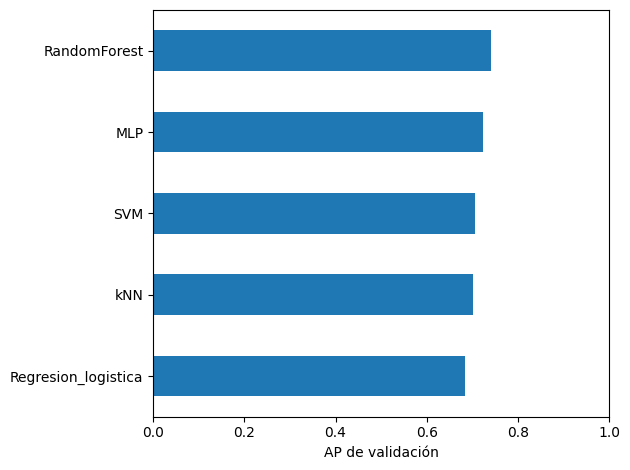

In [4]:
import matplotlib.pyplot as plt
from IPython.display import display

from shopytics.training import validar_finalistas
from shopytics.utils import SEMILLA

finalistas = []
with threadpool_limits(limits=1):
    for familia, modelo in modelos.items():
        tabla = validar_finalistas(modelo, candidatos[familia], X_tr, y_tr, X_va, y_va)
        finalistas.append(tabla.assign(modelo=familia))
finalistas = pd.concat(finalistas, ignore_index=True)
mejores = finalistas.sort_values("AP", ascending=False).drop_duplicates("modelo")
guardar_registros(finalistas, salida / "finalistas.json")
guardar_registros(mejores, salida / "mejores_configuraciones.json")

primero = mejores.iloc[0]
ganador = {"modelo": primero.modelo, "params": primero.params, "AP_validacion": primero.AP,
           "AP_CV": primero.AP_CV, "semilla": SEMILLA, "predictores": PREDICTORAS,
           "criterio": "Mayor AP de validación entre los tres finalistas por AP-CV de cada familia"}
(salida / "ganador.json").write_text(json.dumps(ganador, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
display(mejores[["modelo", "AP_CV", "AP", "ROC_AUC", "params"]].reset_index(drop=True))
ax = mejores.sort_values("AP").plot.barh(x="modelo", y="AP", legend=False)
ax.set(xlabel="AP de validación", ylabel="", xlim=(0, 1))
plt.tight_layout()
plt.show()

## 5. Ablación de variables

¿Aportan señal conjunta las variables que parecían débiles individualmente? Repetimos el experimento de eliminación del proyecto con Random Forest y MLP, manteniendo fijos los hiperparámetros seleccionados para cada familia. Las tres variantes usan exactamente los mismos pliegues y la misma validación.

- **Completo.** Los 17 predictores.
- **Sin candidatas.** Retiramos conjuntamente las variables que el EDA marcó como «eliminar o combinar».
- **Sin redundantes.** En el par de actividad de producto conservamos el conteo, más sencillo de interpretar. En el par de tasas conservamos la que tiene mayor AUC univariado. Así reproducimos la decisión documentada para ambos pares.

Las candidatas se identificaron usando todo el entrenamiento. El cambio de AP en la validación reservada es la comparación principal. Una diferencia positiva significa que la variante obtuvo mayor AP que el pipeline completo de la misma familia.

,modelo,variante,excluidas,AP_CV,AP,delta_AP
0,RandomForest,completo,[],0.757273,0.741404,0.000000
1,RandomForest,sin_candidatas,"[Weekend, Region, Browser, VisitorType, Specia...",0.756609,0.742205,0.000801
2,RandomForest,sin_redundantes,"[ProductRelated_Duration, BounceRates]",0.748463,0.734773,-0.006631
3,MLP,completo,[],0.737548,0.722479,0.000000
4,MLP,sin_candidatas,"[Weekend, Region, Browser, VisitorType, Specia...",0.741343,0.741430,0.018951
5,MLP,sin_redundantes,"[ProductRelated_Duration, BounceRates]",0.735852,0.725033,0.002554


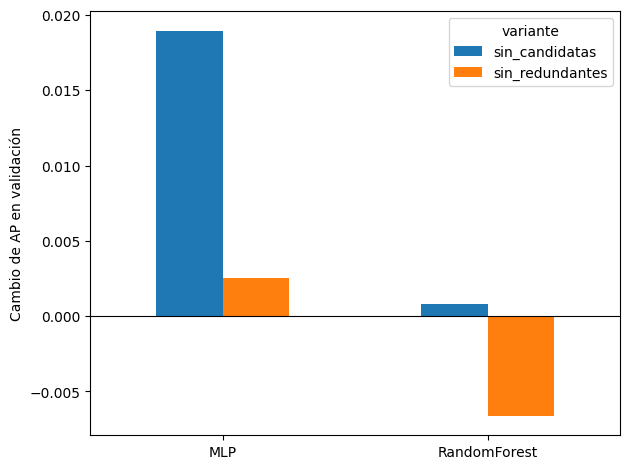

In [5]:
from shopytics.training import evaluar_ablacion

ranking = pd.read_json(eda / "analisis_variables.json").set_index("variable")
pares = pd.read_json(eda / "redundancia_numericas.json")
candidatas = ranking[ranking.recomendacion == "eliminar o combinar"].sort_values("auc_univariado").index.tolist()
redundantes = []
for par in pares.itertuples():
    variables = [par.variable_1, par.variable_2]
    if set(variables) == {"ProductRelated", "ProductRelated_Duration"}:
        redundantes.append("ProductRelated_Duration")
    else:
        redundantes.append(ranking.loc[variables, "auc_univariado"].idxmin())

variantes = {"completo": [], "sin_candidatas": candidatas, "sin_redundantes": redundantes}
params = mejores.set_index("modelo").params
with threadpool_limits(limits=1):
    ablacion = evaluar_ablacion({f: params[f] for f in ["RandomForest", "MLP"]}, variantes,
                                X_tr, y_tr, X_va, y_va)
guardar_registros(ablacion, salida / "ablacion.json")
display(ablacion[["modelo", "variante", "excluidas", "AP_CV", "AP", "delta_AP"]])
ax = ablacion.query("variante != 'completo'").pivot(index="modelo", columns="variante",
                                                      values="delta_AP").plot.bar(rot=0)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(xlabel="", ylabel="Cambio de AP en validación")
plt.tight_layout()
plt.show()

## 6. Interpretación y entrega al notebook 03

La decisión de retirar predictores se evalúa por familia. La configuración ganadora de la sección 4 corresponde al protocolo de selección con los 17 predictores. El resultado de la ablación se conserva por separado para distinguir la elección del clasificador del efecto de simplificar su entrada.

In [6]:
for familia, filas in ablacion.groupby("modelo", sort=False):
    valores = filas.set_index("variante")
    delta = valores.loc["sin_candidatas", "delta_AP"]
    delta_cv = valores.loc["sin_candidatas", "AP_CV"] - valores.loc["completo", "AP_CV"]
    sentido = "aumenta" if delta > 0 else "disminuye" if delta < 0 else "se mantiene"
    print(f"{familia}: con {len(PREDICTORAS) - len(candidatas)} predictores el AP de validación "
          f"{sentido} ({delta:+.4f}); el cambio medio en CV es {delta_cv:+.4f}.")
    print(f"  Con la eliminación por redundancia, el cambio en validación es "
          f"{valores.loc['sin_redundantes', 'delta_AP']:+.4f}.")
print(f"Ganador con los 17 predictores: {ganador['modelo']} (AP = {ganador['AP_validacion']:.4f}).")

RandomForest: con 11 predictores el AP de validación aumenta (+0.0008); el cambio medio en CV es -0.0007.
  Con la eliminación por redundancia, el cambio en validación es -0.0066.
MLP: con 11 predictores el AP de validación aumenta (+0.0190); el cambio medio en CV es +0.0038.
  Con la eliminación por redundancia, el cambio en validación es +0.0026.
Ganador con los 17 predictores: RandomForest (AP = 0.7414).


Para reproducir la reducción de dimensionalidad, el notebook 03 puede leer `resultados/entrenamiento/mejores_configuraciones.json` y `data/dataset_particiones.pkl`. Los pipelines de reducción deben ajustar el preprocesamiento y PCA o UMAP dentro de cada pliegue. El archivo `dataset_particiones_codificadas.pkl` conserva la representación ajustada sobre todo el entrenamiento para el análisis posterior a la selección.